In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
import infrastructure_utils as iu
from statistics import variance

import pykrige.kriging_tools as kt
from pykrige.ok import OrdinaryKriging

# Import Data

In [2]:

# import processed rainfall data
rwn_rain_gps = gpd.read_file('../data/processed/rwn_rain_gps.geojson')
rwn_rain_gps.LAT = rwn_rain_gps.LAT.astype(float)
rwn_rain_gps.LON = rwn_rain_gps.LON.astype(float)
rwn_rain_data_trnpse = pd.read_csv('../data/processed/rainfall_by_station_cols_days_rows_stations.csv')
exceedance_df = pd.read_csv('../data/processed/exceedance_df.csv')



    # District borders
dir_path = '/home/qsel/Desktop/data/consumption_data/'
districts = gpd.read_file(dir_path+'District_Boundaries.geojson')
districts['district'] = districts['district'].str.lower() # convert to lower 

# coloring outside rwanda
africa = gpd.read_file(dir_path+'Africa_Boundaries.geojson')
rwa_neigbors = africa[africa.ISO.isin(['BDI','COD','TZA','UGA'])]

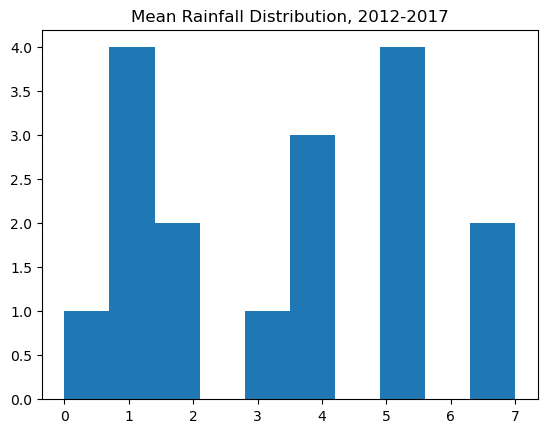

In [3]:

# process rainfall data
rainfall_station_means = rwn_rain_data_trnpse[['stations','mean_rainfall','variance_rainfall']]

# # merge rainfall station locations with mean/variance rainfall recorded at each station
station_gps = rwn_rain_gps.reset_index().rename(columns={'index':'stations'})[['stations','LON','LAT']]
# merge data
station_gps_rain = station_gps.merge(rainfall_station_means) # merge with rainfall means
station_gps_rain = station_gps_rain.merge(exceedance_df) # merge with exceedance days

# input for Ordinary Kriging
lon = np.array(station_gps_rain.LON)
lat = np.array(station_gps_rain.LAT)
mean_rainfall = np.array(station_gps_rain.mean_rainfall)
var_rainfall = np.array(station_gps_rain.variance_rainfall)
exceedance = np.array(station_gps_rain.exceedance_days)

plt.hist(exceedance, bins=10)
plt.title("Mean Rainfall Distribution, 2012-2017")
plt.show()

### import lightning

In [10]:
lightning_df = gpd.read_file('../data/processed/cell_lighting_gdf.geojson')
# lightning_df = pd.read_csv('../data/processed/lightning_points.csv')
# input for Ordinary Kriging
lightning_df = lightning_df.dropna(subset='radiance')
lightning_lon = np.array(lightning_df.longitude)
lightning_lat = np.array(lightning_df.latitude)
# lightning_count = np.array(lightning_df.lightning_count)
lightning_radiance = np.array(lightning_df.radiance)

# Ordinary Kriging

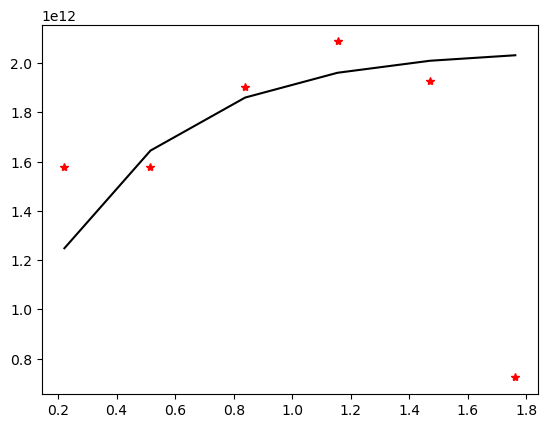

In [11]:
OK_lightning = OrdinaryKriging(
    lightning_lon,
    lightning_lat,
    # lightning_count,
    lightning_radiance,
    variogram_model="exponential", # linear, gaussian, exponential, power
    verbose=False,
    enable_plotting=True,
)

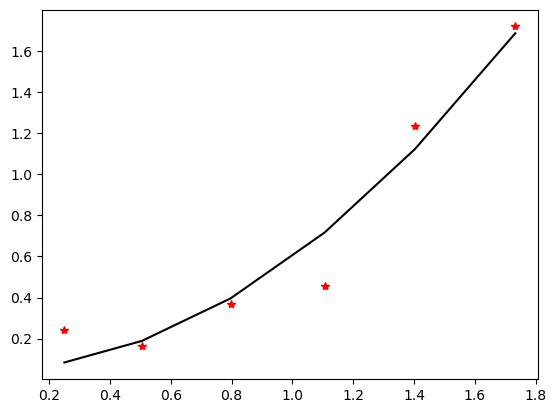

In [4]:
OK_mean = OrdinaryKriging(
    lon,
    lat,
    mean_rainfall,
    variogram_model="power", # linear, gaussian, exponential, power, hole-effect, spherical
    verbose=False,
    enable_plotting=True,
)

OK_var = OrdinaryKriging(lon,lat,var_rainfall,
    variogram_model="linear", # linear, gaussian, exponential, 
    verbose=False,
    enable_plotting=False,
)

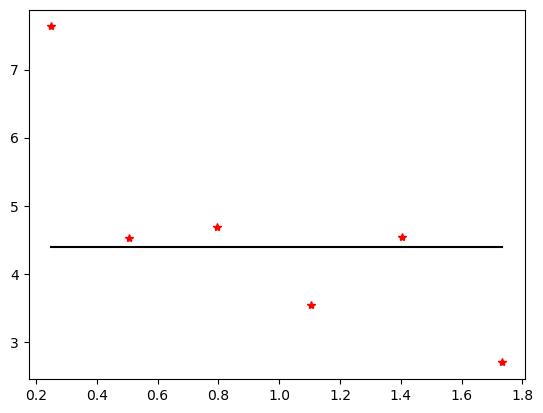

In [29]:
OK_exceedance = OrdinaryKriging(
    lon,
    lat,
    exceedance,
    variogram_model="exponential", # linear, gaussian, exponential, power, hole-effect, spherical
    verbose=False,
    enable_plotting=True,
)

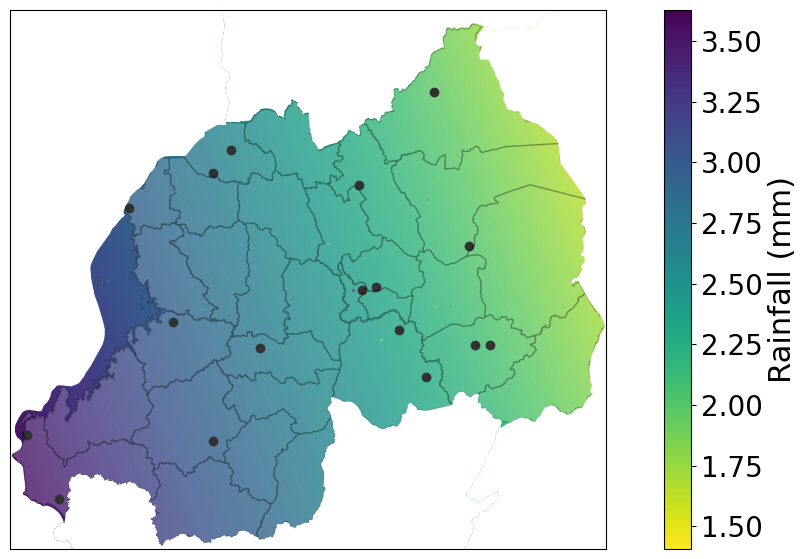

In [32]:
# define grid
grid_lon = np.arange(29.1,31,0.01)
grid_lat = np.arange(-2.92,-1.2,0.01)
z, ss = OK_mean.execute("grid", grid_lon, grid_lat)
tckfz = 20
fontsize = 22
# map grid
fig, ax = plt.subplots(1, figsize = (15, 7))
cax = plt.imshow(z, extent=(28.85,30.9,-2.85,-1), origin='lower', cmap='viridis_r',)
plt.scatter(station_gps_rain.LON,station_gps_rain.LAT, c='k')
districts.plot(ax=ax,alpha=0.2,edgecolor='black',color='white')
rwa_neigbors.plot(ax=ax,color='white')

# station_gps_mean_rain.plot.scatter('LON','LAT')
cbar = plt.colorbar(cax) # -ToDo Inverse colors
ax.set_yticklabels([])
ax.set_xticklabels([])
ax.set_xticks([])
ax.set_yticks([])
ax.set_title('')
ax.set_facecolor('white')
cb_ax = fig.axes[1] 
cb_ax.tick_params(labelsize=tckfz)
plt.tick_params(left = False, right = False , labelleft = False ,
                labelbottom = False, bottom = False)
cbar.set_label("Rainfall (mm)",fontsize=fontsize)
plt.xlim(28.85,30.9)
plt.ylim(-2.85,-1)
plt.show()

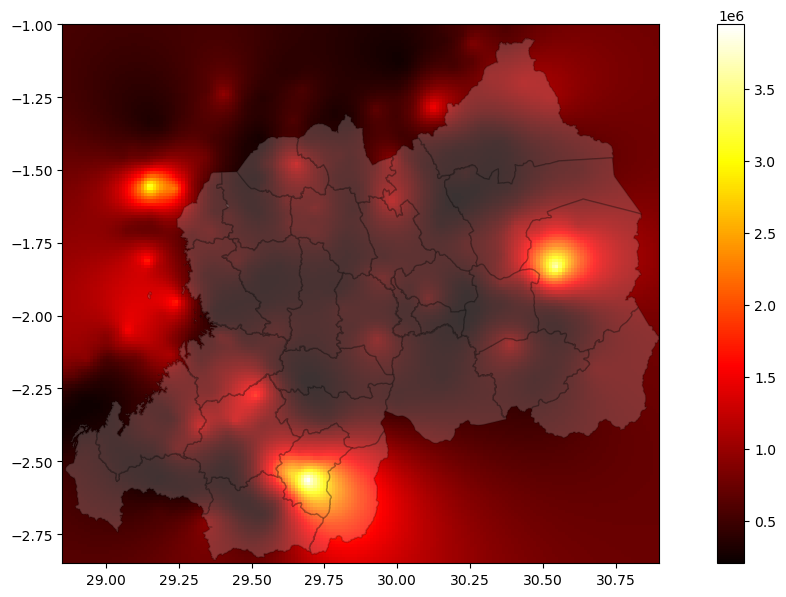

In [14]:
# define grid
grid_lon = np.arange(29.1,31,0.01)
grid_lat = np.arange(-2.92,-1.2,0.01)
z, ss = OK_lightning.execute("grid", grid_lon, grid_lat)

# map grid
fig, ax = plt.subplots(1, figsize = (15, 7))
cax = plt.imshow(z, extent=(28.85,30.9,-2.85,-1), origin='lower', cmap='hot')
districts.plot(ax=ax,alpha=0.2,edgecolor='black',color='white')
cbar = plt.colorbar(cax, cmap='Reds') # -ToDo Inverse colors
plt.show()

/tmp/ipykernel_3139331/84793190.py:5: RuntimeWarning: invalid value encountered in sqrt
  cax = plt.imshow(np.sqrt(ss), extent=(28.9,30.6,-3,-1), origin='lower', vmin=0)


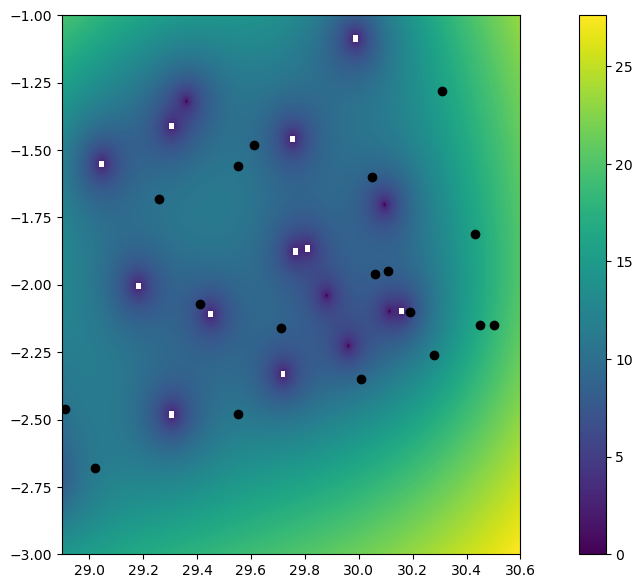

In [102]:
## Uncertainity

# map grid
fig, ax = plt.subplots(1, figsize = (15, 7))
cax = plt.imshow(np.sqrt(ss), extent=(28.9,30.6,-3,-1), origin='lower', vmin=0)
plt.scatter(station_gps_rain.LON,station_gps_rain.LAT, c='k')
# station_gps_mean_rain.plot.scatter('LON','LAT')
cbar = plt.colorbar(cax)
plt.show()

# Merge Pole, rainfall and lightning data

#### Import  data

In [7]:
# cells
# load pole distance dataset
# cell_pole_dist_df = pd.read_pickle('../data/processed/cell_pole_dist_df.pck')
# cell_pole_dist_gdf = gpd.GeoDataFrame(cell_pole_dist_df, geometry=cell_pole_dist_df.geometry)

# load survey data
eicv_file = '/home/qsel/Desktop/data/REG_electricity_expenditure/EICV5_Person_Household_Shared_13_02_2023v.csv'
eicv_HH = pd.read_csv(eicv_file, encoding='latin-1', low_memory=False)
survey = iu.get_survey_geopandas_df(eicv_HH, geo_crs='epsg:4326', project_crs='epsg:32735', project=False)

In [16]:
## villages
# load pole distance dataset
village_pole_dist_df = pd.read_pickle('../data/processed/village_pole_dist_df.pck')
village_pole_dist_gdf = gpd.GeoDataFrame(village_pole_dist_df, geometry=village_pole_dist_df.geometry)

# load survey data
eicv_file = '/home/qsel/Desktop/data/REG_electricity_expenditure/EICV5_Person_Household_Shared_13_02_2023v.csv'
eicv_HH = pd.read_csv(eicv_file, encoding='latin-1', low_memory=False)
survey = iu.get_survey_geopandas_df(eicv_HH, geo_crs='epsg:4326', project_crs='epsg:32735', project=False)

### Kriging Predictions

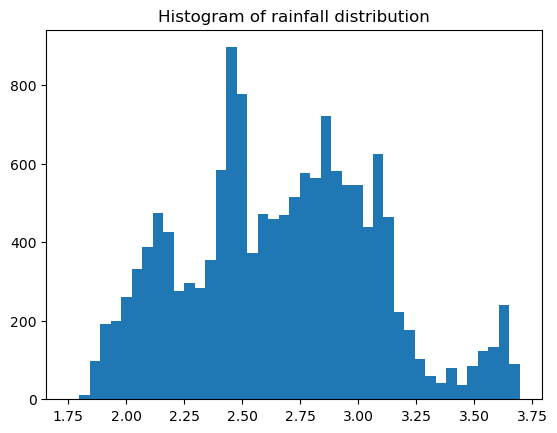

In [12]:
# implement kriging Predictions
survey_lon = np.array(survey.longitude)
survey_lat = np.array(survey.lat)
predict_mean_rain, ss = OK_mean.execute('points',survey_lon,survey_lat)
predict_var_rain, ss = OK_var.execute('points',survey_lon,survey_lat)
predict_mean_lightning_rad, ss = OK_lightning.execute('points',survey_lon,survey_lat)

# distribution
plt.hist(predict_mean_rain, bins='auto')
plt.title("Histogram of rainfall distribution")
plt.show()

### Note: averaging over cell provides a better result than averaging over village

In [36]:
# merge instrument variables with survey data
survey['mean_rainfall'] = predict_mean_rain
survey['var_rainfall']  = predict_var_rain
survey['lightning_rad']  = predict_mean_lightning_rad

    # merge pole distances
# survey_instrument_vars = survey.sjoin(cell_pole_dist_gdf).drop(columns='index_right')
survey_instrument_vars = survey.copy() 
survey_instrument_vars = survey_instrument_vars[['hhid','mean_rainfall','lightning_rad']].rename(columns={'mean_rainfall':'krig_mean_rainfall','lightning_rad':'krig_lightning_rad'})
survey_instrument_vars

,hhid,krig_mean_rainfall,krig_lightning_rad
0,200001,2.472546,385745.237606
2,200002,2.472714,385879.234099
6,200003,2.473131,385381.381149
10,200004,2.473144,385258.740377
13,200005,2.473031,385187.885284
...,...,...,...
64291,214576,2.619352,433327.240237
64297,214577,2.618077,436009.819952
64303,214578,2.617697,436963.167698
64304,214579,2.617615,437353.155872


### Save files

In [38]:
# survey_pole_dist.to_pickle('../data/processed/survey_pole_dist.pck')
survey_instrument_vars.to_csv('../data/processed/survey_instrument_vars_11_30_23.csv',index=False)